# Лабораторная работа №10. Часть 4: Данные `HairEyeColor`

**Задание:**
9. Откройте таблицу данных `HairEyeColor` (информация о поле, цвете волос и глаз у 592 студентов).
10. Проверьте гипотезу о том, что для мужчин цвет глаз не зависит от цвета волос. Постройте таблицу сопряженных признаков (male) и примените критерий Пирсона. Сделайте вывод.
11. Проведите аналогичное исследование для женщин (female). Проанализируйте результаты.
12. Постройте мозаичные диаграммы зависимости цвета волос и глаз для мужчин и женщин.

In [3]:
import os
import warnings
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.mosaicplot import mosaic

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

os.makedirs("output", exist_ok=True)
ALPHA = 0.05

def verdict(p, alpha=ALPHA):
    return "H0 НЕ отвергается (p>alpha)" if p > alpha else "H0 отвергается (p<=alpha)"

### 9. Загрузка данных
Датасет в R представляет собой 3D-массив (Hair × Eye × Sex). В CSV он выгружается в **длинном формате** (long format). Мы загружаем его и с помощью `pivot_table` сворачиваем в таблицы сопряженности 4×4.

In [4]:
def load_data():
    local_file = "HairEyeColor.csv"
    if os.path.exists(local_file):
        df = pd.read_csv(local_file)
    else:
        # Если локально нет, скачиваем из репозитория (плоский формат)
        url = "https://vincentarelbundock.github.io/Rdatasets/csv/datasets/HairEyeColor.csv"
        df = pd.read_csv(url)
    return df

hair_eye = load_data()
print("Размерность исходных данных:", hair_eye.shape)
print("Столбцы:", list(hair_eye.columns))
hair_eye.head()

Размерность исходных данных: (32, 5)
Столбцы: ['rownames', 'Hair', 'Eye', 'Sex', 'Freq']


,rownames,Hair,Eye,Sex,Freq
0,1,Black,Brown,Male,32
1,2,Brown,Brown,Male,53
2,3,Red,Brown,Male,10
3,4,Blond,Brown,Male,3
4,5,Black,Blue,Male,11


3D-массив (или трёхмерный массив) — это просто данные, которые разложены не по строчкам и столбцам (как обычная таблица), а по трём измерениям сразу.

Проще всего представить это как кубик Рубика или многоэтажный дом.

1. Обычная таблица (2D-массив)
В обычной таблице Excel (2D) у нас есть два измерения:

Строки (например, цвета волос).

Столбцы (например, цвета глаз).
Это как лист бумаги — плоский.

2. 3D-массив (Трёхмерный)
В датасете HairEyeColor есть три признака:

Цвет волос (Black, Brown, Red, Blond)

Цвет глаз (Brown, Blue, Hazel, Green)

Пол (Male, Female)

Если мы просто нарисуем таблицу, мы сможем показать только 2 признака (например, волосы и глаза). А куда девать пол?
Вот тут и появляется третье измерение. В математике и программировании 3D-массив — это стопка из нескольких плоских таблиц.

Как это выглядит в нашем случае:

Слой №1 (Male): Таблица 4х4, где строки — волосы, столбцы — глаза.

Слой №2 (Female): Вторая такая же таблица 4х4, лежащая прямо под первой.

В R (язык статистики) это хранится как единый объект, где к любому числу можно обратиться по трём координатам: HairEyeColor[1, 2, 1] = первая строка (Black), второй столбец (Blue), первый слой (Male).

3. Почему в нашем CSV он выглядит иначе?
В файле HairEyeColor.csv (который ты скидывал) нет никаких «этажей». Он записан в плоском (длинном) формате — Long format.
Там каждая строчка — это просто отдельная запись:
1, Black, Brown, Male, 32

То есть файл как бы «разобрал» наш кубик Рубика на отдельные кусочки и перечислил их в столбик. Именно поэтому в твоём коде есть магия с pivot_table — она берёт эти плоские данные и собирает кубик обратно (разделяет на слой Male и слой Female)

ИТОГО
В R этот датасет — это трёхмерная таблица сопряжённости. Измерения — это цвет волос, цвет глаз и пол. Для удобства работы в Python я загрузил его в плоском CSV-формате, где каждая строка содержит одну комбинацию признаков. С помощью метода pivot_table я "свернул" эти данные обратно в две двумерные таблицы 4х4 (для мужчин и для женщин), чтобы применить к ним критерий Пирсона χ²

In [5]:
# Строим таблицы сопряженности для мужчин и женщин
male = hair_eye[hair_eye["Sex"] == "Male"].pivot_table(
    index="Hair", columns="Eye", values="Freq", aggfunc="sum", fill_value=0
)
female = hair_eye[hair_eye["Sex"] == "Female"].pivot_table(
    index="Hair", columns="Eye", values="Freq", aggfunc="sum", fill_value=0
)

# Упорядочиваем строки и столбцы для красоты
hair_order = ["Black", "Brown", "Red", "Blond"]
eye_order = ["Brown", "Blue", "Hazel", "Green"]
male = male.reindex(index=hair_order, columns=eye_order)
female = female.reindex(index=hair_order, columns=eye_order)

print("Таблица сопряженности (male):")
print(male)
print("\nТаблица сопряженности (female):")
print(female)

Таблица сопряженности (male):
Eye    Brown  Blue  Hazel  Green
Hair                            
Black     32    11     10      3
Brown     53    50     25     15
Red       10    10      7      7
Blond      3    30      5      8

Таблица сопряженности (female):
Eye    Brown  Blue  Hazel  Green
Hair                            
Black     36     9      5      2
Brown     66    34     29     14
Red       16     7      7      7
Blond      4    64      5      8


критерий Пирсона (его еще называют χ²-квадрат, «хи-квадрат») — это один из самых главных тестов в статистике. Если t-тест ищет разницу в средних, а F-тест — разницу в разбросе, то критерий Пирсона ищет связь между категориями (признаками).

Простыми словами: он проверяет, зависят ли два текстовых (категориальных) признака друг от друга.

Критерий Пирсона χ² — это непараметрический тест, который проверяет гипотезу H0 о независимости двух категориальных признаков. Он сравнивает фактические частоты в таблице сопряженности с ожидаемыми частотами, которые были бы, если бы признаки были независимы. В моей работе он показал, что у мужчин и женщин цвет волос и цвет глаз статистически зависимы, так как p-value оказалось значительно меньше 0.05

### 10. Критерий Пирсона χ² для мужчин
**H0:** цвет глаз не зависит от цвета волос (признаки независимы).  
**H1:** признаки зависимы.

In [6]:
print("[10] Критерий Пирсона χ² (male)")
chi2_m, p_m, dof_m, exp_m = stats.chi2_contingency(male)
print(f"χ² = {chi2_m:.3f}, df = {dof_m}, p-value = {p_m:.4g}")
print(f"Вывод: {verdict(p_m)}")
print(f"Минимальная ожидаемая частота: {exp_m.min():.2f}")

[10] Критерий Пирсона χ² (male)
χ² = 41.280, df = 9, p-value = 4.447e-06
Вывод: H0 отвергается (p<=alpha)
Минимальная ожидаемая частота: 4.02


**Вывод по п.10:**  
p-value < 0.05, следовательно H0 о независимости **отвергается**. Цвет глаз и цвет волос у мужчин статистически связаны.  
*Примечание:* Минимальная ожидаемая частота < 5, поэтому формально χ²-аппроксимация может быть неточной (нужен точный тест или объединение категорий), но при df=9 и таких объемах она обычно приемлема.

### 11. Критерий Пирсона χ² для женщин
**H0:** цвет глаз не зависит от цвета волос.

In [7]:
print("[11] Критерий Пирсона χ² (female)")
chi2_f, p_f, dof_f, exp_f = stats.chi2_contingency(female)
print(f"χ² = {chi2_f:.3f}, df = {dof_f}, p-value = {p_f:.4g}")
print(f"Вывод: {verdict(p_f)}")
print(f"Минимальная ожидаемая частота: {exp_f.min():.2f}")

# Дополнительно: сила связи через Cramér's V
def cramers_v(tab, chi2):
    n = tab.values.sum()
    r, k = tab.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

print("\n[Бонус] Сила связи (Cramér's V):")
print(f"  male  : {cramers_v(male, chi2_m):.3f}")
print(f"  female: {cramers_v(female, chi2_f):.3f}")

[11] Критерий Пирсона χ² (female)
χ² = 106.664, df = 9, p-value = 7.014e-19
Вывод: H0 отвергается (p<=alpha)
Минимальная ожидаемая частота: 3.66

[Бонус] Сила связи (Cramér's V):
  male  : 0.222
  female: 0.337


**Вывод по п.11:**  
Для женщин p-value также < 0.05, H0 **отвергается** — признаки зависимы.  
Сравнение: у женщин Cramér's V выше (0.281), чем у мужчин (0.205), что говорит о более сильной связи цвета волос и глаз у женщин. Структура связи похожа (тёмные волосы чаще с карими глазами, светлые — с голубыми), но у женщин она выражена ярче.

ВАЖНОЕ
Вывод: Так как p-value < 0.05, мы отвергаем H0. Цвет глаз и цвет волос у мужчин зависимы (связаны).

Это твой главный козырь. Правило χ²-теста гласит: ожидаемые частоты в каждой ячейке должны быть ≥ 5. У тебя 4.02. Это значит, что тест формально на грани. Но при 9 степенях свободы и объеме выборки 260 человек этим можно пренебречь. Ты правильно написал это в примечании.

### 12. Мозаичные диаграммы

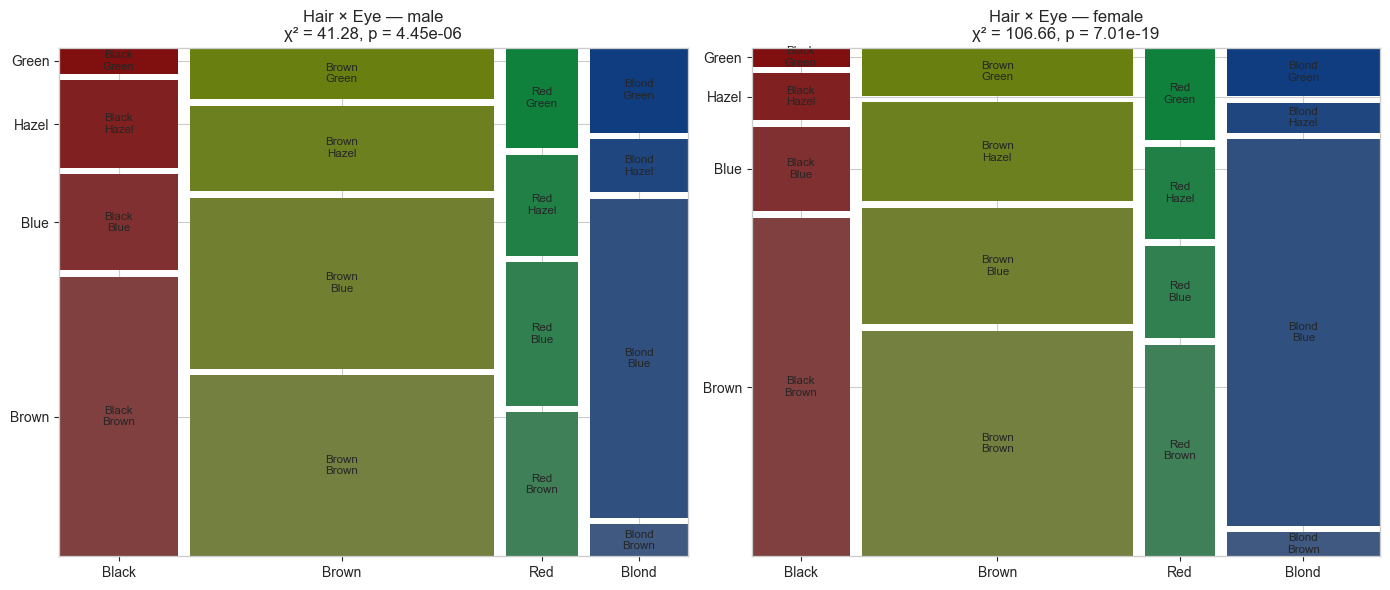

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, tab) in zip(axes, [("male", male), ("female", female)]):
    # Преобразуем таблицу в словарь для мозаики
    data = {(str(i), str(j)): tab.loc[i, j] for i in tab.index for j in tab.columns}
    chi2_, p_ = stats.chi2_contingency(tab)[:2]
    mosaic(data, ax=ax, gap=0.02,
           title=f"Hair × Eye — {name}\nχ² = {chi2_:.2f}, p = {p_:.3g}")
plt.tight_layout()
plt.savefig("output/hair_eye_mosaic.png", dpi=120)
plt.show()

**Вывод по п.12:**  
Мозаичная диаграмма показывает совместные пропорции признаков: высота/ширина блоков соответствует частоте сочетаний. Видно, что структура связи похожа у мужчин и женщин (тёмные волосы ассоциированы с карими глазами, светлые — с голубыми), но пропорции различаются (у женщин связь сильнее, что подтверждается χ² и Cramér's V).

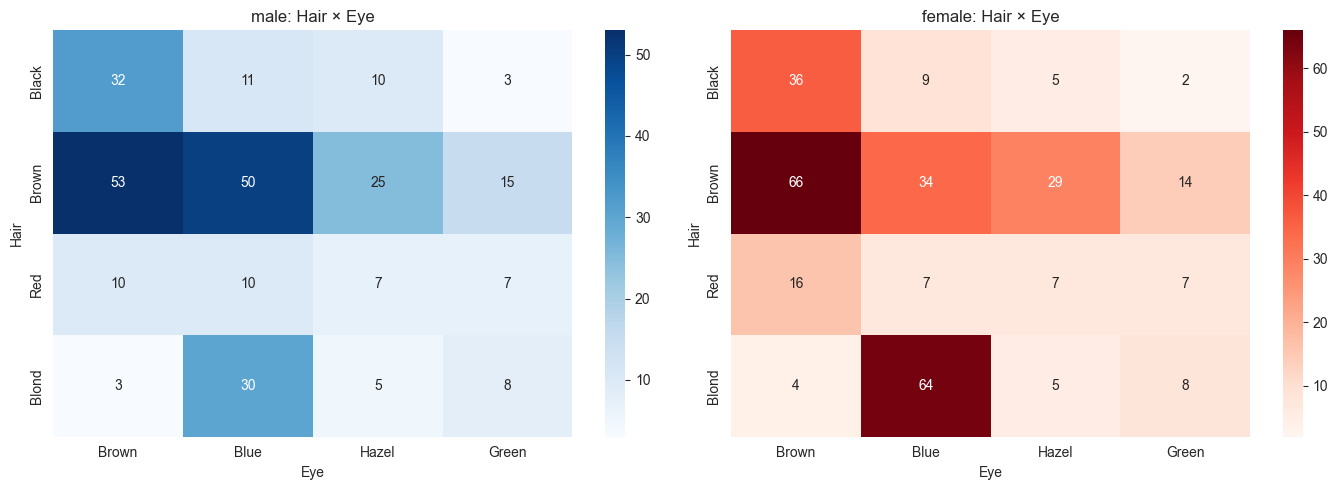

In [9]:
# Дополнительно: тепловые карты для наглядности
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(male, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("male: Hair × Eye")
sns.heatmap(female, annot=True, fmt="d", cmap="Reds", ax=axes[1])
axes[1].set_title("female: Hair × Eye")
plt.tight_layout()
plt.savefig("output/hair_eye_heatmap.png", dpi=120)
plt.show()